In [1]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf


<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [2]:
# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:,3]
b_x

array([81.73284, 81.72514, 81.72964, ..., 86.88986, 86.86479, 86.90699],
      dtype=float32)

In [3]:
df= pd.DataFrame({'datetime':datetime,
                  'b_x':b_x,
                  'b_y':b_y,
                  'b_z':b_z  
                 }).set_index(datetime)
df

,datetime,b_x,b_y,b_z
2015-10-28 00:00:10.963242,2015-10-28 00:00:10.963242,81.732841,-181.288544,445.587585
2015-10-28 00:00:11.088244,2015-10-28 00:00:11.088244,81.725143,-181.284271,445.566803
2015-10-28 00:00:11.213246,2015-10-28 00:00:11.213246,81.729637,-181.289795,445.544617
2015-10-28 00:00:11.338247,2015-10-28 00:00:11.338247,81.757286,-181.283447,445.520325
2015-10-28 00:00:11.463249,2015-10-28 00:00:11.463249,81.760918,-181.282104,445.496582
...,...,...,...,...
2015-10-29 00:00:11.490561,2015-10-29 00:00:11.490561,86.900932,-159.191711,395.277039
2015-10-29 00:00:11.615562,2015-10-29 00:00:11.615562,86.917961,-159.204590,395.254395
2015-10-29 00:00:11.740564,2015-10-29 00:00:11.740564,86.889862,-159.177521,395.238434
2015-10-29 00:00:11.865566,2015-10-29 00:00:11.865566,86.864792,-159.139099,395.226074


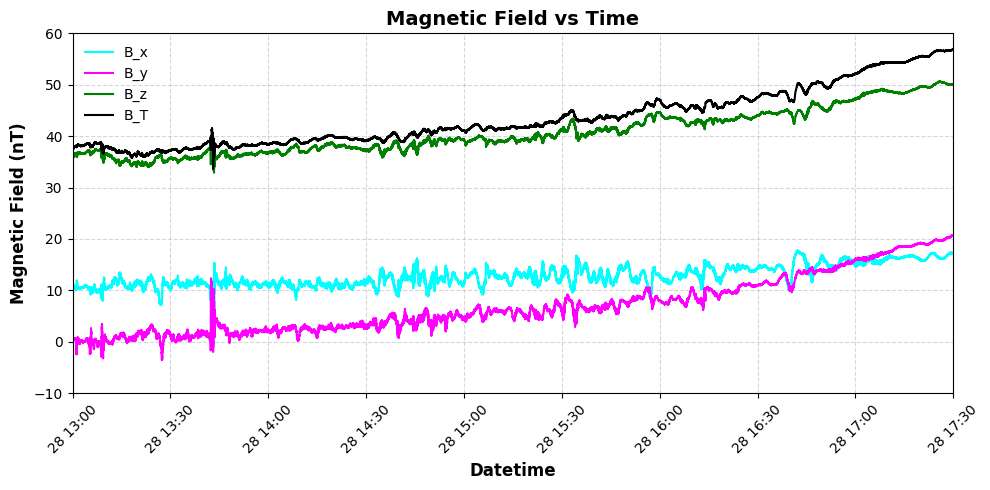

In [4]:
import matplotlib.pyplot as plt

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(df['datetime'], b_x, label='B_x', color='cyan')
plt.plot(df['datetime'], b_y, label='B_y', color='magenta')
plt.plot(df['datetime'], b_z, label='B_z', color='green')
plt.plot(df['datetime'], b_t, label='B_T', color='black')
# Set y-axis limits
plt.ylim(-10, 60)

# Set x-axis limits to focus on the desired time range
# Convert the datetime range to pandas Timestamp
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')

plt.xlim(start_time, end_time)

# Add labels and title
plt.xlabel('Datetime', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field vs Time', fontsize=14, fontweight='bold')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Add grid and legend
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field and time values
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']


# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz
fs= sampling_freq

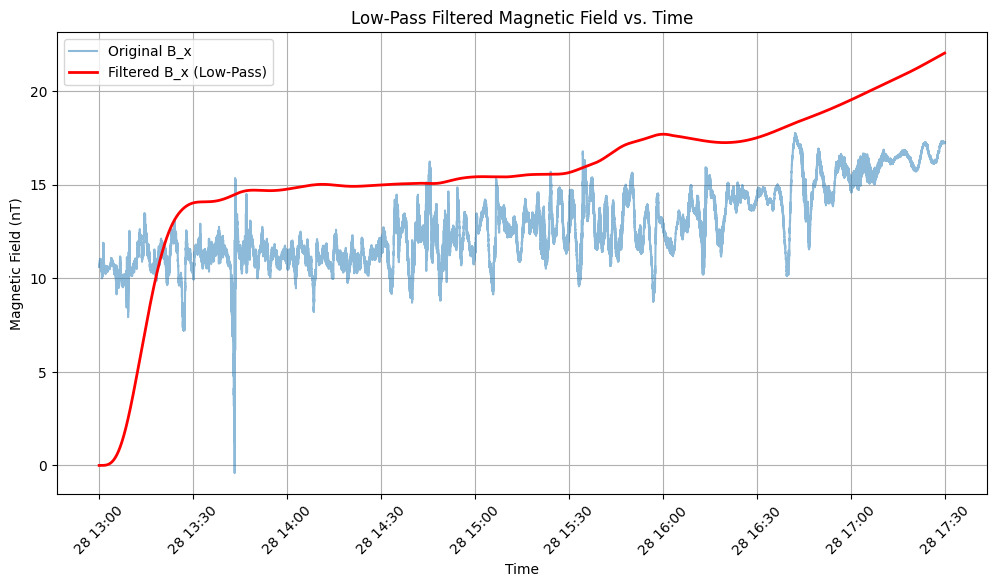

In [7]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import butter, lfilter
import matplotlib.pyplot as plt

# # Load the CDF file
# cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
# cdf = pycdf.CDF(cdf_path)

# # Extract the magnetic field data and timestamps
# datetime = pd.to_datetime(cdf['Epoch'][:])
# b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
# b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
# b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]

# # Create DataFrame
# df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z}).set_index('datetime')

# # Filter data for the desired time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')
# filtered_df = df.loc[start_time:end_time]

# # Extract magnetic field and time values
# b_x_filtered = filtered_df['b_x'].values
# time_filtered = filtered_df.index

# Compute Sampling Frequency
time_diff = np.diff(time_filtered.astype('int64')) / 1e9  # Convert nanoseconds to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = lfilter(b, a, data)
    return y

# Apply Low-Pass Filter
cutoff = 0.0005 # Hz
order = 4  # Filter order
b_x_filtered_lp = butter_lowpass_filter(b_x_filtered, cutoff, sampling_freq, order)

# Plot the Original and Filtered Magnetic Field Data
plt.figure(figsize=(12, 6))
plt.plot(time_filtered, b_x_filtered, label='Original B_x', alpha=0.5)
plt.plot(time_filtered, b_x_filtered_lp, label='Filtered B_x (Low-Pass)', color='red', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Magnetic Field (nT)')
plt.title('Low-Pass Filtered Magnetic Field vs. Time')
plt.legend()
plt.grid()
plt.xticks(rotation=45)
plt.show()


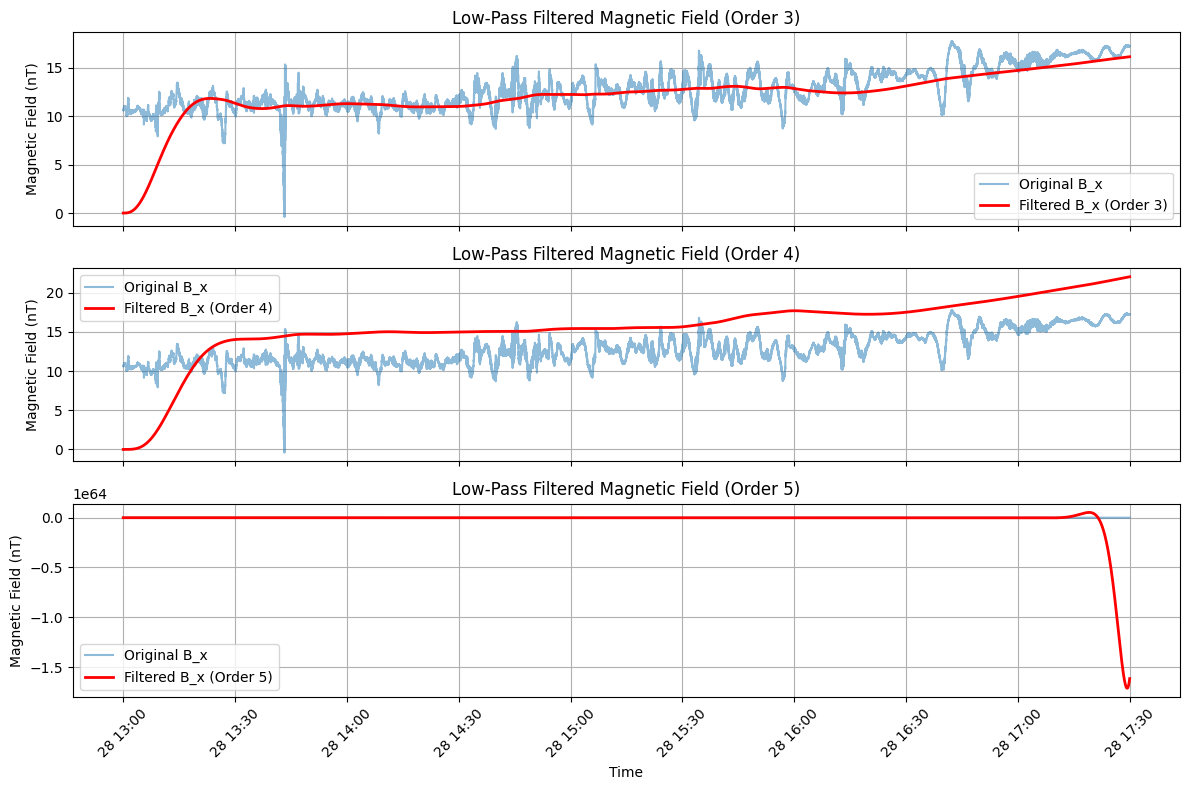

In [8]:
# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = lfilter(b, a, data)
    return y

# Define cutoff frequency
cutoff = 0.0005  # Hz

# Apply Low-Pass Filter for different orders
orders = [3, 4, 5]
filtered_data = {order: butter_lowpass_filter(b_x_filtered, cutoff, sampling_freq, order) for order in orders}

# Plot Subplots
fig, axes = plt.subplots(len(orders), 1, figsize=(12, 8), sharex=True)

for i, order in enumerate(orders):
    axes[i].plot(time_filtered, b_x_filtered, label='Original B_x', alpha=0.5)
    axes[i].plot(time_filtered, filtered_data[order], label=f'Filtered B_x (Order {order})', color='red', linewidth=2)
    axes[i].set_ylabel('Magnetic Field (nT)')
    axes[i].set_title(f'Low-Pass Filtered Magnetic Field (Order {order})')
    axes[i].legend()
    axes[i].grid()

# Common X-axis settings
axes[-1].set_xlabel('Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
fs

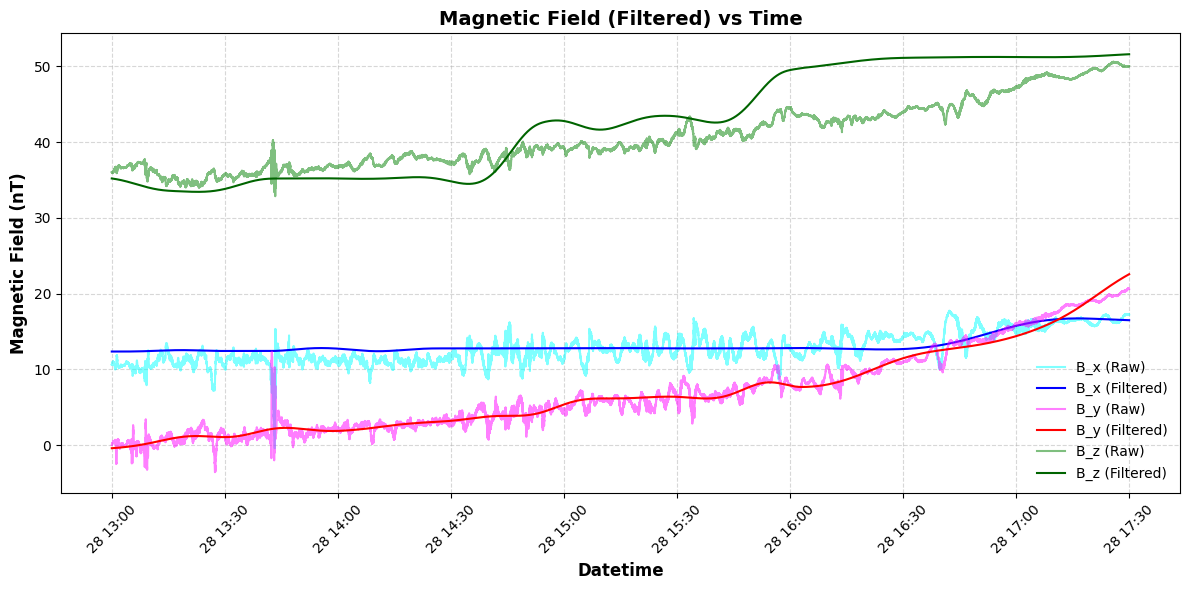

In [15]:
import pandas as pd
from spacepy import pycdf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)

# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:, 3]

# Create DataFrame
df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z, 'b_t': b_t}).set_index('datetime')

# Compute Sampling Frequency
time_diff = np.diff(df.index.astype('int64')) / 1e9  # Convert nanoseconds to seconds
fs = 1 / np.mean(time_diff)  # Hz

# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    return filtfilt(b, a, data)  # Use filtfilt for zero-phase filtering

# Apply Low-Pass Filter
cutoff_freq = 0.0005  # Hz
df['b_x_f'] = butter_lowpass_filter(df['b_x'], cutoff_freq, fs)
df['b_y_f'] = butter_lowpass_filter(df['b_y'], cutoff_freq, fs)
df['b_z_f'] = butter_lowpass_filter(df['b_z'], cutoff_freq, fs)
df['b_t_f'] = butter_lowpass_filter(df['b_t'], cutoff_freq, fs)
# Define time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')

# Filter dataframe for plotting
df_filtered = df.loc[start_time:end_time]

# Plot original vs. filtered magnetic field data
plt.figure(figsize=(12, 6))
plt.plot(df_filtered.index, df_filtered['b_x'], label='B_x (Raw)', color='cyan', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['b_x_f'], label='B_x (Filtered)', color='blue')
plt.plot(df_filtered.index, df_filtered['b_y'], label='B_y (Raw)', color='magenta', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['b_y_f'], label='B_y (Filtered)', color='red')
plt.plot(df_filtered.index, df_filtered['b_z'], label='B_z (Raw)', color='green', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['b_z_f'], label='B_z (Filtered)', color='darkgreen')

# Labels, title, and formatting
plt.xlabel('Datetime', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field (Filtered) vs Time', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)
plt.tight_layout()
plt.show()


In [29]:
mean_b_t_f = np.mean(df['b_t_f'])
B = mean_b_t_f
B

np.float64(371.9974139825807)

In [ ]:
theta = np.degrees(np.arccos(-B_z / B)) 

In [25]:
costheta = A*B/(np.abs(A)*np.abs(B))
costheta

np.float64(1.0)

In [27]:
theta = np.arccos(costheta)
theta

np.float64(0.0)

In [34]:
# %run Hodogram-filtered-B.ipynb